# Model comparison: CVD prediction (MICHD)

Compares linear models for predicting cardiovascular disease, using 5-fold cross-validation and F1 of the positive class as the main metric (only 8.8% of people have CVD).

**Models**
- Least squares, ridge regression, and MSE with GD / SGD
- Logistic and regularized logistic regression
- Class imbalance: weighted logistic regression (positive weight 1.5–3) and random undersampling
- Feature expansion: polynomial features (degree 2–3) and pairwise interactions of the main risk factors

In [21]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data
from implementations import (
    least_squares,
    ridge_regression,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
)
from utils import (
    load_preprocess,
    build_k_indices,
    threshold_curve,
    add_interactions,
    INTERACTION_FEATURES,
    f1_score,
    predict,
    step_size,
    weighted_reg_logistic_regression,
    add_powers,
    random_undersample,
)
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")

In [2]:
QUICK = False
K= 5  
MAX_ITERS = 1000  
SGD_ITERS = 100_000  
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
POS_WEIGHTS = [1.5, 2, 3] # how much more a positive sample counts (weighted logistic)

os.makedirs("results", exist_ok=True)
np.random.seed(0) 

## Loading Data 

In [3]:
tx, _, y, _, features = load_preprocess()
if QUICK:
    keep = np.random.default_rng(0).choice(len(y), min(50_000, len(y)), replace=False)
    tx, y = tx[keep], y[keep]
y01 = (y == 1).astype(float)  # logistic regression needs labels 0/1
N, D = tx.shape
k_indices = build_k_indices(y, K, seed=1)
w0 = np.zeros(D)
gamma_mse = step_size(tx, "mse")
gamma_sgd = 0.1 / np.mean(np.sum(tx**2, axis=1))  # one sample's curvature is ||x_n||^2
print(f"N={N}  D={D}  positives={y01.mean():.1%}  quick mode: {QUICK}")

N=328135  D=249  positives=8.8%  quick mode: False


## Cross-validation 

In [ ]:
def cross_validation(y, y01, tx, k_indices, k, train):
    """Train on all folds except the k-th one (same split as lab 4).

    Args:
        y, y01:     labels in {-1, 1} and {0, 1}, shape=(N,)
        tx:         data matrix, shape=(N, D)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold is the validation fold
        train:      function train(y_pm, y01, tx) -> w

    Returns:
        w, te_indice, tr_indice: the weights and the validation / training row indices
    """
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)].reshape(-1)
    w = train(y[tr_indice], y01[tr_indice], tx[tr_indice])
    return w, te_indice, tr_indice


def cross_validate(model, param, train):
    """Run cross_validation() for every fold, tune the threshold and summarize.
    
    """
    start = time.time()
    oof_scores = np.full(N, np.nan) 
    fitted = []
    for k in range(K):
        try:
            w, te_indice, tr_indice = cross_validation(y, y01, tx, k_indices, k, train)
        except np.linalg.LinAlgError as err:  
            print(f"{model:<22} {param:<16} failed: {err}")
            return None
        oof_scores[te_indice] = tx[te_indice] @ w
        fitted.append((te_indice, tr_indice, w))

    used = k_indices.reshape(-1)  
    thresholds, f1s = threshold_curve(oof_scores[used], y[used])
    t = thresholds[np.argmax(f1s)]
    val_f1 = [f1_score(y[te], predict(oof_scores[te], t)) for te, _, _ in fitted]
    val_acc = [np.mean(predict(oof_scores[te], t) == y[te]) for te, _, _ in fitted]
    train_f1 = [f1_score(y[tr], predict(tx[tr] @ w, t)) for _, tr, w in fitted]
    
    # default threshold: score 0 (sigmoid 0.5 for logistic, midpoint of -1/1 for MSE)
    f1_0 = [f1_score(y[te], predict(oof_scores[te], 0.0)) for te, _, _ in fitted]
    acc_0 = [np.mean(predict(oof_scores[te], 0.0) == y[te]) for te, _, _ in fitted]

    r = dict(
        model=model,
        param=param,
        f1=np.mean(val_f1),
        f1_std=np.std(val_f1),
        acc=np.mean(val_acc),
        acc_std=np.std(val_acc),
        train_f1=np.mean(train_f1),
        f1_default=np.mean(f1_0),
        f1_default_std=np.std(f1_0),
        acc_default=np.mean(acc_0),
        acc_default_std=np.std(acc_0),
        threshold=t,
        curve=(thresholds, f1s),
    )
    print(
        f"{model:<22} {param:<16} F1 {r['f1']:.4f} ± {r['f1_std']:.4f}   acc {r['acc']:.4f}   "
        f"train F1 {r['train_f1']:.4f}   ({time.time() - start:.0f}s)"
    )
    return r

results = []

def run(model, param, train):
    """Cross-validate one setting and store its result."""
    r = cross_validate(model, param, train)
    if r is not None:
        results.append(r)
    return r

## Models

In [5]:
# Least squares and ridge regression for every lambda
run("least squares", "-", lambda yp, y01_, x: least_squares(yp, x)[0])
for lam in LAMBDAS:
    run("ridge", f"lambda={lam:g}", lambda yp, y01_, x, lam=lam: ridge_regression(yp, x, lam)[0])

least squares          -                F1 0.4135 ± 0.0037   acc 0.8544   train F1 0.4148   (4s)
ridge                  lambda=1e-05     F1 0.4135 ± 0.0036   acc 0.8544   train F1 0.4148   (4s)
ridge                  lambda=0.0001    F1 0.4135 ± 0.0037   acc 0.8544   train F1 0.4147   (4s)
ridge                  lambda=0.001     F1 0.4132 ± 0.0041   acc 0.8572   train F1 0.4151   (3s)
ridge                  lambda=0.01      F1 0.4129 ± 0.0036   acc 0.8630   train F1 0.4141   (4s)
ridge                  lambda=0.1       F1 0.4078 ± 0.0031   acc 0.8677   train F1 0.4084   (3s)


In [6]:
# Linear regression with gradient descent and stochastic gradient descent
run(
    "MSE GD",
    f"gamma={gamma_mse:.3g}",
    lambda yp, y01_, x: mean_squared_error_gd(yp, x, w0, MAX_ITERS, gamma_mse)[0],
)
run(
    "MSE SGD",
    f"gamma={gamma_sgd:.3g}",
    lambda yp, y01_, x: mean_squared_error_sgd(yp, x, w0, SGD_ITERS, gamma_sgd)[0],
)

MSE GD                 gamma=0.0898     F1 0.4130 ± 0.0047   acc 0.8689   train F1 0.4151   (72s)
MSE SGD                gamma=0.0007     F1 0.3760 ± 0.0094   acc 0.8451   train F1 0.3779   (4s)


{'model': 'MSE SGD',
 'param': 'gamma=0.0007',
 'f1': np.float64(0.3760169297803507),
 'f1_std': np.float64(0.00943801721761348),
 'acc': np.float64(0.8451277675347036),
 'acc_std': np.float64(0.007890600241493725),
 'train_f1': np.float64(0.377919805751302),
 'f1_default': np.float64(0.12508468474251933),
 'f1_default_std': np.float64(0.06764625626976517),
 'acc_default': np.float64(0.9127279930516403),
 'acc_default_std': np.float64(0.0011169339324549016),
 'threshold': np.float64(-0.5810099754234613),
 'curve': (array([-0.87617047, -0.87328359, -0.87026487, -0.86728132, -0.86429131,
         -0.86117227, -0.85815878, -0.85512839, -0.85210306, -0.84891946,
         -0.84592266, -0.84282504, -0.83963655, -0.83634408, -0.83297457,
         -0.82961777, -0.82631489, -0.82300796, -0.81967108, -0.81624119,
         -0.81279489, -0.80920991, -0.80576857, -0.80229255, -0.79875665,
         -0.79521428, -0.79155523, -0.78791481, -0.78413039, -0.78043327,
         -0.77659737, -0.7727844 , -0

In [7]:
# Logistic regression and regularized logistic regression for every lambda
g = step_size(tx, "logistic")
run("logistic", "-", lambda yp, y01_, x, g=g: logistic_regression(y01_, x, w0, MAX_ITERS, g)[0])

for lam in LAMBDAS:
    g = step_size(tx, "logistic", lam)
    run(
        "reg logistic",
        f"lambda={lam:g}",
        lambda yp, y01_, x, lam=lam, g=g: reg_logistic_regression(y01_, x, lam, w0, MAX_ITERS, g)[0],
    )

logistic               -                F1 0.4265 ± 0.0033   acc 0.8691   train F1 0.4286   (121s)
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
reg logistic           lambda=1e-05     F1 0.4272 ± 0.0038   acc 0.8721   train F1 0.4288   (122s)
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
reg logistic           lambda=0.0001    F1 0.4273 ± 0.0041   acc 0.8721   train F1 0.4289   (121s)
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
reg logistic           lambda=0.001     F1 0.4268 ± 0.0037   acc 0.8691   train F1 0.4284   (119s)
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
reg logistic           lambda=0.01      F1 0.4194 ± 0.0028   acc 0.8646   train F1 0.4203   (117s)
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
[0. 1.]
reg logistic           lambda=0.1       F1 0.3982 ± 0.0022   acc 0.8566   train F1 0.3983   (119s)


In [8]:
# Weighted logistic regression for every lambda and positive weight
# uses best lambda from regularized logistic regression
best_reg = max((r for r in results if r["model"] == "reg logistic"), key=lambda r: r["f1"])
best_lam = float(best_reg["param"].split("=")[1])

for pw in POS_WEIGHTS:
    g = step_size(tx, "logistic", best_lam, y01, pw)
    run(
        "weighted reg logistic",
        f"lambda={best_lam:g} pw={pw}",
        lambda yp, y01_, x, pw=pw, g=g: weighted_reg_logistic_regression(
            y01_, x, best_lam, w0, MAX_ITERS, g, pw
        ),
    )

weighted reg logistic  lambda=0.0001 pw=1.5 F1 0.4264 ± 0.0030   acc 0.8691   train F1 0.4278   (75s)
weighted reg logistic  lambda=0.0001 pw=2 F1 0.4265 ± 0.0031   acc 0.8691   train F1 0.4278   (74s)
weighted reg logistic  lambda=0.0001 pw=3 F1 0.4261 ± 0.0031   acc 0.8690   train F1 0.4279   (75s)


### Class imbalance: unregularized class weight and undersampling

In [9]:
# Class weight 3 without regularization (lambda = 0)
g = step_size(tx, "logistic", 0.0, y01, 3)
run(
    "weighted logistic",
    "pw=3",
    lambda yp, y01_, x, g=g: weighted_reg_logistic_regression(y01_, x, 0.0, w0, MAX_ITERS, g, 3),
)

# Random undersampling of the majority class, on the training folds only
# Validation fold keeps the real class balance: und_ratio=1 -> balanced training set.
UND_RATIO = 1

def train_undersampled(yp, y01_, x):
    x_und, y_und = random_undersample(x, y01_, UND_RATIO, seed=0)
    g = step_size(x_und, "logistic")
    return logistic_regression(y_und, x_und, w0, MAX_ITERS, g)[0]


run("undersampled logistic", f"ratio={UND_RATIO}", train_undersampled)

weighted logistic      pw=3             F1 0.4260 ± 0.0031   acc 0.8690   train F1 0.4279   (75s)
undersampled logistic  ratio=1          F1 0.4252 ± 0.0032   acc 0.8745   train F1 0.4270   (25s)


{'model': 'undersampled logistic',
 'param': 'ratio=1',
 'f1': np.float64(0.4252352975404466),
 'f1_std': np.float64(0.0031692347359113084),
 'acc': np.float64(0.8745242049766103),
 'acc_std': np.float64(0.0016360589679845737),
 'train_f1': np.float64(0.42701475798248334),
 'f1_default': np.float64(0.37393397613319723),
 'f1_default_std': np.float64(0.0042184799415329955),
 'acc_default': np.float64(0.761729166349216),
 'acc_default_std': np.float64(0.001194109267084619),
 'threshold': np.float64(1.0451535844496007),
 'curve': (array([-1.08526631, -1.0596179 , -1.03445676, -1.00874226, -0.98270887,
         -0.95767513, -0.93217213, -0.90749051, -0.88291215, -0.85843204,
         -0.83296581, -0.80828924, -0.78263971, -0.75764265, -0.73132046,
         -0.70580777, -0.67950248, -0.65346093, -0.62724012, -0.60068204,
         -0.57527504, -0.54865332, -0.52355785, -0.49624155, -0.4707652 ,
         -0.4439145 , -0.41814585, -0.39298393, -0.36759056, -0.34043037,
         -0.3143356 , -0

### Polynomial Features

In [10]:
# Polynomial features: x^2, ..., x^degree for the non-binary columns (like build_poly in lab 4),
# on the best regularized logistic setting found above.
DEGREES = [2, 3]

# keep the class weight only if it beat plain regularized logistic regression
best_w = max((r for r in results if r["model"] == "weighted reg logistic"), key=lambda r: r["f1"])
best_pw = float(best_w["param"].split("pw=")[1]) if best_w["f1"] > best_reg["f1"] else 1.0

tx_base = tx
try:
    for degree in DEGREES:
        tx, _, _ = add_powers(tx_base, features, degree)  # cross_validate() uses the global tx
        print(f"degree {degree}: {tx.shape[1]} features")
        g = step_size(tx, "logistic", best_lam, y01, best_pw)
        w0_poly = np.zeros(tx.shape[1])
        run(
            "poly reg logistic",
            f"lambda={best_lam:g} pw={best_pw:g} degree={degree}",
            lambda yp, y01_, x, g=g, w0_poly=w0_poly: weighted_reg_logistic_regression(
                y01_, x, best_lam, w0_poly, MAX_ITERS, g, best_pw
            ),
        )
finally:
    tx = tx_base  # back to the original features for the next cells

degree 2: 318 features
poly reg logistic      lambda=0.0001 pw=1 degree=2 F1 0.4263 ± 0.0032   acc 0.8748   train F1 0.4294   (95s)
degree 3: 387 features
poly reg logistic      lambda=0.0001 pw=1 degree=3 F1 0.4261 ± 0.0036   acc 0.8747   train F1 0.4288   (116s)


### Interaction features 

In [11]:
# Interaction features: products x_i * x_j of the main risk factors on the best regularized logistic setting found above.
best_lam, best_pw = 1e-4, 2.0  

used = [n for n in INTERACTION_FEATURES if n in features]
print(f"{len(used)} features combined pairwise: {used}")
print(f"not found after preprocessing: {[n for n in INTERACTION_FEATURES if n not in features]}")

tx_base = tx
try:
    tx, _, _ = add_interactions(tx_base, features)  # cross_validate() uses the global tx
    print(f"{tx.shape[1] - tx_base.shape[1]} interaction features added, {tx.shape[1]} in total")
    g = step_size(tx, "logistic", best_lam, y01, best_pw)
    w0_inter = np.zeros(tx.shape[1])
    run(
        "interact reg logistic",
        f"lambda={best_lam:g} pw={best_pw:g} interactions=1",
        lambda yp, y01_, x, g=g, w0_inter=w0_inter: weighted_reg_logistic_regression(
            y01_, x, best_lam, w0_inter, MAX_ITERS, g, best_pw
        ),
    )
finally:
    tx = tx_base  

17 features combined pairwise: ['_AGEG5YR', 'SEX', 'GENHLTH', 'PHYSHLTH', '_BMI5', 'BPHIGH4=1', 'TOLDHI2', 'DIABETE3=1', '_SMOKER3', 'CVDSTRK3', 'CHCCOPD1', 'CHCKIDNY', 'DIFFWALK', 'USEEQUIP', 'QLACTLM2', 'HAVARTH3', 'EMPLOY1=7']
not found after preprocessing: ['_RFHYPE5']
136 interaction features added, 385 in total
interact reg logistic  lambda=0.0001 pw=2 interactions=1 F1 0.4283 ± 0.0040   acc 0.8752   train F1 0.4318   (116s)


In [12]:
print(f"THRESHOLD = {results[-1]['threshold']:.6f}")

THRESHOLD = -0.601730


## Results

In [13]:
with open("results/cv_results.csv", "w") as f:
    f.write("model,param,val_f1,val_f1_std,val_acc,val_acc_std,train_f1,threshold\n")
    for r in results:
        f.write(
            f"{r['model']},{r['param']},{r['f1']:.4f},{r['f1_std']:.4f},{r['acc']:.4f},"
            f"{r['acc_std']:.4f},{r['train_f1']:.4f},{r['threshold']:.6f}\n"
        )

print(f"{'model':<22} {'param':<16} {'val F1':>16} {'val acc':>8} {'train F1':>9}")
for r in sorted(results, key=lambda r: -r["f1"]):
    print(
        f"{r['model']:<22} {r['param']:<16} {r['f1']:.4f} ± {r['f1_std']:.4f} "
        f"{r['acc']:>8.4f} {r['train_f1']:>9.4f}"
    )

model                  param                      val F1  val acc  train F1
interact reg logistic  lambda=0.0001 pw=2 interactions=1 0.4283 ± 0.0040   0.8752    0.4318
reg logistic           lambda=0.0001    0.4273 ± 0.0041   0.8721    0.4289
reg logistic           lambda=1e-05     0.4272 ± 0.0038   0.8721    0.4288
reg logistic           lambda=0.001     0.4268 ± 0.0037   0.8691    0.4284
weighted reg logistic  lambda=0.0001 pw=2 0.4265 ± 0.0031   0.8691    0.4278
logistic               -                0.4265 ± 0.0033   0.8691    0.4286
weighted reg logistic  lambda=0.0001 pw=1.5 0.4264 ± 0.0030   0.8691    0.4278
poly reg logistic      lambda=0.0001 pw=1 degree=2 0.4263 ± 0.0032   0.8748    0.4294
poly reg logistic      lambda=0.0001 pw=1 degree=3 0.4261 ± 0.0036   0.8747    0.4288
weighted reg logistic  lambda=0.0001 pw=3 0.4261 ± 0.0031   0.8690    0.4279
weighted logistic      pw=3             0.4260 ± 0.0031   0.8690    0.4279
undersampled logistic  ratio=1          0.4252 ± 0.0

## Table: class imbalance and threshold tuning (TT)

In [14]:
def find(model, param=None):
    return next(r for r in results if r["model"] == model and (param is None or r["param"] == param))


table_rows = [
    ("Baseline", find("logistic")),
    ("Undersampling", find("undersampled logistic")),
    ("Class weight 3", find("weighted logistic", "pw=3")),
    ("Reg. class weight 2", find("weighted reg logistic", f"lambda={best_lam:g} pw=2")),
]

lines = []
for name, r in table_rows:
    lines.append((name, r["f1_default"], r["f1_default_std"], r["acc_default"], r["acc_default_std"]))
    lines.append((name + " + TT", r["f1"], r["f1_std"], r["acc"], r["acc_std"]))

print(f"{'Model':<26} {'F1':>16} {'Accuracy':>16}")
for name, f1, f1s, acc, accs in lines:
    print(f"{name:<26} {f1:.4f} ± {f1s:.4f}  {acc:.4f} ± {accs:.4f}")

# LaTeX rows (booktabs), ready to paste in the report
print("\\toprule\nModel & F1 & Accuracy \\\\\n\\midrule")
for name, f1, f1s, acc, accs in lines:
    print(f"{name} & {f1:.3f} $\\pm$ {f1s:.3f} & {acc:.3f} $\\pm$ {accs:.3f} \\\\")
print("\\bottomrule")

Model                                    F1         Accuracy
Baseline                   0.2308 ± 0.0038  0.9145 ± 0.0015
Baseline + TT              0.4265 ± 0.0033  0.8691 ± 0.0008
Undersampling              0.3739 ± 0.0042  0.7617 ± 0.0012
Undersampling + TT         0.4252 ± 0.0032  0.8745 ± 0.0016
Class weight 3             0.4175 ± 0.0047  0.8893 ± 0.0012
Class weight 3 + TT        0.4260 ± 0.0031  0.8690 ± 0.0008
Reg. class weight 2        0.3756 ± 0.0044  0.9057 ± 0.0014
Reg. class weight 2 + TT   0.4265 ± 0.0031  0.8691 ± 0.0008
\toprule
Model & F1 & Accuracy \\
\midrule
Baseline & 0.231 $\pm$ 0.004 & 0.915 $\pm$ 0.001 \\
Baseline + TT & 0.426 $\pm$ 0.003 & 0.869 $\pm$ 0.001 \\
Undersampling & 0.374 $\pm$ 0.004 & 0.762 $\pm$ 0.001 \\
Undersampling + TT & 0.425 $\pm$ 0.003 & 0.875 $\pm$ 0.002 \\
Class weight 3 & 0.418 $\pm$ 0.005 & 0.889 $\pm$ 0.001 \\
Class weight 3 + TT & 0.426 $\pm$ 0.003 & 0.869 $\pm$ 0.001 \\
Reg. class weight 2 & 0.376 $\pm$ 0.004 & 0.906 $\pm$ 0.001 \\
Reg.

## Figure: model comparison

Best hyperparameters of each model, with the tuned threshold.

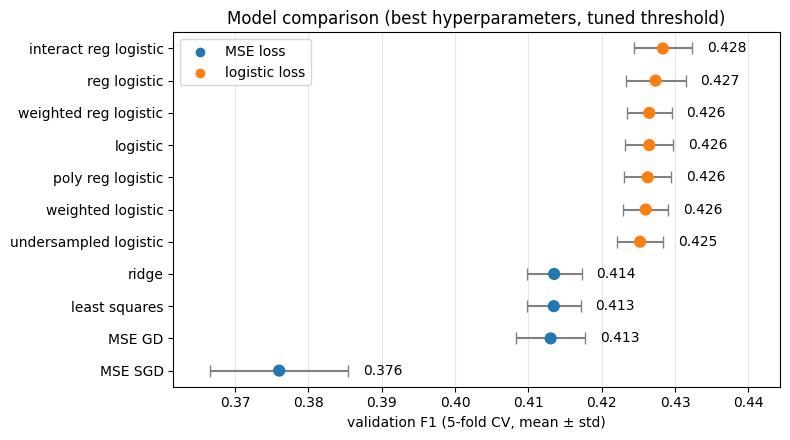

In [15]:
# best version of each model, sorted by validation F1
families = list(dict.fromkeys(r["model"] for r in results))
bests = [max((r for r in results if r["model"] == m), key=lambda r: r["f1"]) for m in families]
bests.sort(key=lambda r: r["f1"])

fig, ax = plt.subplots(figsize=(8, 4.5))
y_pos = np.arange(len(bests))
colors = ["tab:orange" if "logistic" in r["model"] else "tab:blue" for r in bests]
ax.errorbar(
    [r["f1"] for r in bests],
    y_pos,
    xerr=[r["f1_std"] for r in bests],
    fmt="none",
    ecolor="gray",
    capsize=4,
)
ax.scatter([r["f1"] for r in bests], y_pos, c=colors, s=60, zorder=3)
for i, r in enumerate(bests):
    ax.text(r["f1"] + r["f1_std"] + 0.002, i, f"{r['f1']:.3f}", va="center")
ax.set_yticks(y_pos, [r["model"] for r in bests])
lo = min(r["f1"] - r["f1_std"] for r in bests)
hi = max(r["f1"] + r["f1_std"] for r in bests)
ax.set_xlim(lo - 0.005, hi + 0.012)  # zoom on the range of the results
ax.set_xlabel(f"validation F1 ({K}-fold CV, mean ± std)")
ax.set_title("Model comparison (best hyperparameters, tuned threshold)")
ax.scatter([], [], c="tab:blue", label="MSE loss")
ax.scatter([], [], c="tab:orange", label="logistic loss")
ax.legend(loc="upper left")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=150)
plt.show()

## Figure: F1 vs $\lambda$ (bias–variance)

- **Train much higher than validation**: overfitting (small $\lambda$).
- **Both dropping**: underfitting (large $\lambda$).

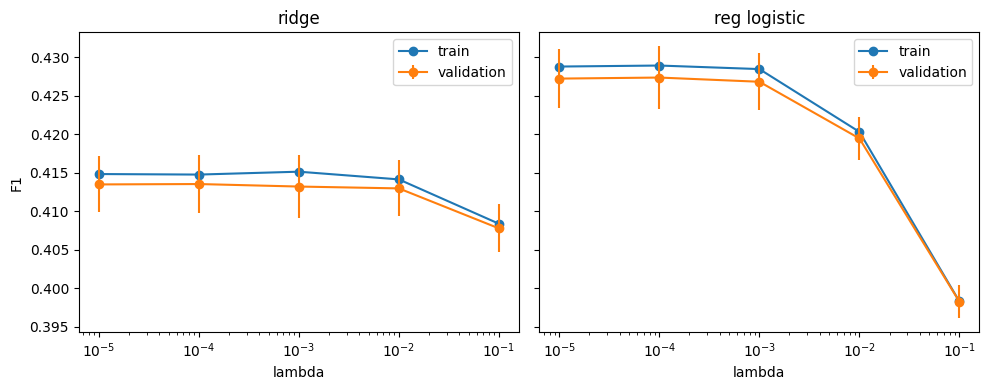

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, model in zip(axes, ["ridge", "reg logistic"]):
    rs = [r for r in results if r["model"] == model]
    lams = [float(r["param"].split("=")[1]) for r in rs]
    ax.semilogx(lams, [r["train_f1"] for r in rs], "o-", label="train")
    ax.errorbar(lams, [r["f1"] for r in rs], yerr=[r["f1_std"] for r in rs], fmt="o-", label="validation")
    ax.set_xlabel("lambda")
    ax.set_title(model)
    ax.legend()
axes[0].set_ylabel("F1")
fig.tight_layout()
fig.savefig("results/f1_vs_lambda.png", dpi=150)
plt.show()

## Figure: F1 vs decision threshold (best model)

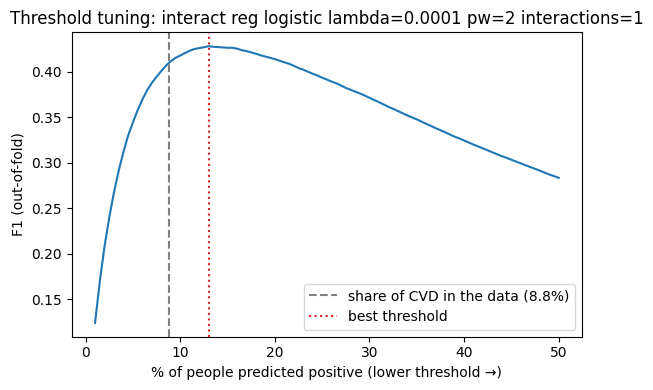

In [17]:
best = max(results, key=lambda r: r["f1"])
thresholds, f1s = best["curve"]
share_positive = 1 - np.linspace(0.50, 0.99, 99)  # fraction of people predicted positive per threshold

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(share_positive * 100, f1s)
ax.axvline(y01.mean() * 100, color="gray", linestyle="--", label=f"share of CVD in the data ({y01.mean():.1%})")
ax.axvline(share_positive[np.argmax(f1s)] * 100, color="tab:red", linestyle=":", label="best threshold")
ax.set_xlabel("% of people predicted positive (lower threshold →)")
ax.set_ylabel("F1 (out-of-fold)")
ax.set_title(f"Threshold tuning: {best['model']} {best['param']}")
ax.legend()
fig.tight_layout()
fig.savefig("results/f1_vs_threshold.png", dpi=150)
plt.show()

**Interpretation.** Each point is a candidate threshold, shown as the share of people it predicts as positive. A strict threshold (left) gives high precision but misses most CVD cases. A loose threshold flags many healthy people. F1 peaks at ≈ 0.43 when ~13% of people are predicted positive, which corresponds to a score threshold of −0.60 (p ≈ 0.35). That is more than the true CVD share of 8.8%. 
The curve is flat around the peak (≈ 10–17%), so the chosen threshold should carry over well to the test set.

## feature-importance

[0. 1.]


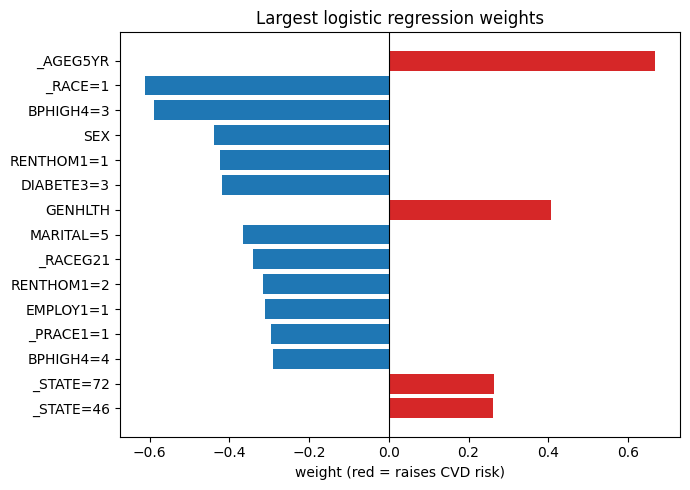

In [18]:
# train the best regularized logistic model on all data and show its largest weights
w_full, _ = reg_logistic_regression(y01, tx, best_lam, w0, MAX_ITERS, step_size(tx, "logistic", best_lam))
top = np.argsort(-np.abs(w_full[1:]))[:15] + 1  # skip the bias (index 0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(np.array(features)[top][::-1], w_full[top][::-1],
        color=np.where(w_full[top][::-1] > 0, "tab:red", "tab:blue"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("weight (red = raises CVD risk)")
ax.set_title("Largest logistic regression weights")
fig.tight_layout()
fig.savefig("results/top_weights.png", dpi=150)
plt.show()

**Interpretation.** Largest weights of the regularized logistic model trained on all the data. Numeric features are standardized, so their weights are comparable in size.

- **Strongest risk factors:** age (`_AGEG5YR`) has the largest positive weight, followed by worse self-rated health (`GENHLTH`, where higher = worse).
- **Protective categories:**
  - no high blood pressure (`BPHIGH4=3`) and no diabetes (`DIABETE3=3`)
  - being female (`SEX`, 2 = female)
  - being employed (`EMPLOY1=1`)
  - never married (`MARITAL=5`)
- **Regional effects:** Puerto Rico (`_STATE=72`) and South Dakota (`_STATE=46`) have higher predicted risk than other states, possibly also reflecting differences in how the survey was run.
- **Race and housing** (`_RACE=1`, `_RACEG21`, `_PRACE1=1`, `RENTHOM1`) also carry large weights.

## Caught vs missed CVD cases

interact reg logistic lambda=0.0001 pw=2 interactions=1
caught 3123 of 5840 CVD cases (recall 53.5%)


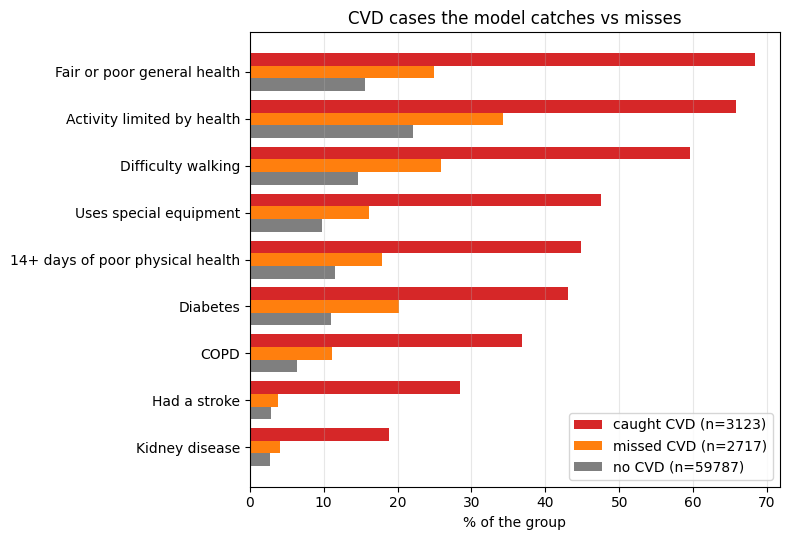

In [22]:
# Caught vs missed: among the people who really have CVD, how do the ones the model catches
# differ from the ones it misses? Best logistic model, trained on folds 2-5, analysed on fold 1.

r = max(
    (r for r in results if "logistic" in r["model"] and "undersampled" not in r["model"]),
    key=lambda r: r["f1"],
)
s = dict(p.split("=") for p in r["param"].split() if "=" in p)
lam, pw, degree = float(s.get("lambda", 0)), float(s.get("pw", 1)), int(s.get("degree", 1))

x_all = add_powers(tx, features, degree)[0] if degree > 1 else tx
if s.get("interactions") == "1":
    x_all = add_interactions(x_all, features)[0]
g = step_size(x_all, "logistic", lam, y01, pw)


def train(yp, y01_, x):
    return weighted_reg_logistic_regression(y01_, x, lam, np.zeros(x.shape[1]), MAX_ITERS, g, pw)


w, te, _ = cross_validation(y, y01, x_all, k_indices, 0, train)
pred = predict(x_all[te] @ w, r["threshold"])

is_cvd = y[te] == 1
caught = te[is_cvd & (pred == 1)]   # CVD cases the model predicts as CVD
missed = te[is_cvd & (pred == -1)]  # CVD cases the model misses
no_cvd = te[~is_cvd]
print(f"{r['model']} {r['param']}")
print(f"caught {len(caught)} of {len(caught) + len(missed)} CVD cases (recall {len(caught) / (len(caught) + len(missed)):.1%})")

# % of each group with a given condition, from the raw survey answers
x_raw = load_csv_data("data")[0]
if QUICK:
    x_raw = x_raw[keep]
raw_names = open("data/x_train.csv").readline().strip().split(",")[1:]
c = {n: i for i, n in enumerate(raw_names)}

yes = lambda v: v == 1
yesno = lambda v: np.isin(v, [1, 2])  # ignore don't know / refused / missing
conditions = [
    ("Had a stroke", "CVDSTRK3", yes, yesno),
    ("COPD", "CHCCOPD1", yes, yesno),
    ("Kidney disease", "CHCKIDNY", yes, yesno),
    ("Diabetes", "DIABETE3", yes, lambda v: np.isin(v, [1, 2, 3, 4])),
    ("Difficulty walking", "DIFFWALK", yes, yesno),
    ("Uses special equipment", "USEEQUIP", yes, yesno),
    ("Activity limited by health", "QLACTLM2", yes, yesno),
    ("Fair or poor general health", "GENHLTH", lambda v: v >= 4, lambda v: np.isin(v, [1, 2, 3, 4, 5])),
    ("14+ days of poor physical health", "PHYSHLTH", lambda v: (v >= 14) & (v <= 30), lambda v: (v <= 30) | (v == 88)),
]
groups = [("caught CVD", caught, "tab:red"), ("missed CVD", missed, "tab:orange"), ("no CVD", no_cvd, "tab:gray")]


def share(rows, name, cond, valid):
    v = x_raw[rows, c[name]]
    v = v[valid(v)]
    return 100 * np.mean(cond(v))


table = np.array([[share(rows, col, cond, valid) for _, rows, _ in groups] for _, col, cond, valid in conditions])
order = np.argsort(table[:, 0])  # sort by share among caught cases

fig, ax = plt.subplots(figsize=(8, 5.5))
h = 0.27
pos = np.arange(len(conditions))
for i, (label, rows, color) in enumerate(groups):
    ax.barh(pos + (1 - i) * h, table[order, i], height=h, color=color, label=f"{label} (n={len(rows)})")
ax.set_yticks(pos, [conditions[i][0] for i in order])
ax.set_xlabel("% of the group")
ax.set_title("CVD cases the model catches vs misses")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("results/caught_vs_missed.png", dpi=150)
plt.show()

The model essentially flags people with many comorbidities (red), whereas missed cases (orange) look much closer to people without CVD (gray) than to the caught ones. This also relates to the nature of the survey and data : the survey has no direct cardiac measurement so a person with CVD who otherwise feels healthy and has no other conditions is considered a non CVD case.


## Settings for `run.py`

Only copy these from a run with `QUICK = False`.

In [20]:
print(f"best: {best['model']} {best['param']}  F1 {best['f1']:.4f} ± {best['f1_std']:.4f}")
if QUICK:
    print("(quick mode: set QUICK = False and re-run before copying settings into run.py)")
settings = dict(p.split("=") for p in best["param"].split() if "=" in p)
extended = ("poly reg logistic", "interact reg logistic")
model = "weighted reg logistic" if best["model"] in extended else best["model"]
print("\nsettings to copy into run.py:")
print(f'MODEL = "{model}"')
print(f"LAMBDA = {settings.get('lambda', '0')}")
print(f"POS_WEIGHT = {settings.get('pw', '1')}")
print(f"DEGREE = {settings.get('degree', '1')}")
print(f"INTERACTIONS = {settings.get('interactions', '0') == '1'}")
print(f"THRESHOLD = {best['threshold']:.6f}")

best: interact reg logistic lambda=0.0001 pw=2 interactions=1  F1 0.4283 ± 0.0040

settings to copy into run.py:
MODEL = "weighted reg logistic"
LAMBDA = 0.0001
POS_WEIGHT = 2
DEGREE = 1
INTERACTIONS = True
THRESHOLD = -0.601730
